# 8. Componente espacial (2.7) y espacio-temporal (2.8)

Obligatorio porque el dataset trae `Latitude` y `Longitude`. La ficha del dataset las
describe como la ubicación de la **tienda**; en los datos hay **una coordenada por
cliente** (cada cliente tiene siempre la misma), ubicada en EE. UU. y Puerto Rico.
El **destino** del pedido no tiene coordenadas: solo país, región y mercado (en 164
países). Por eso el análisis espacial con coordenadas describe el **origen** del pedido,
y el destino se analiza por unidad geográfica.

Las medidas de autocorrelación siguen a {cite}`anselin_1995` (LISA) y {cite}`getis_ord_1992` (Gi\*).
Para proteger la privacidad y estabilizar las tasas, las métricas espaciales se calculan
sobre **celdas de 1° × 1°** (≈ 100 km) con al menos 30 líneas. Solo entrenamiento.

In [1]:
from pathlib import Path
import re, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

project_root = Path.cwd().resolve()
while not (project_root / "_config.yml").exists():
    if project_root.parent == project_root:
        raise FileNotFoundError("No se encontró _config.yml. Ejecuta el notebook dentro de la carpeta del libro.")
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

for _folder in ("tables", "figures"):          # se crean si no existen
    (project_root / _folder).mkdir(exist_ok=True)

from src.project_utils import *

configure_plots()
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 70)
TABLES = project_root / "tables"

def md_out(text):
    display(Markdown(text))

from scipy import stats
from scipy.spatial import ConvexHull
from sklearn.cluster import DBSCAN
train = load_train()
y = train[TARGET]
rng = np.random.default_rng(RANDOM_STATE)

## Validación de coordenadas

In [2]:
lat, lon = train[LAT], train[LON]
AREAS = {"continental": (24, 50, -125, -66), "Puerto Rico": (17.8, 18.6, -67.5, -65.1),
         "Hawái": (18.5, 22.5, -161, -154), "Alaska": (51, 72, -170, -129)}
def zona(la, lo):
    for k, (a, b, c, d) in AREAS.items():
        if a <= la <= b and c <= lo <= d:
            return k
    return "fuera del área"
pts = train.groupby([LAT, LON]).agg(lineas=(TARGET, "size"), estado=("customer_state", "first"), ciudad=("customer_city", "first")).reset_index()
pts["zona"] = [zona(a, b) for a, b in zip(pts[LAT], pts[LON])]
decimales = lat.astype(str).str.split(".").str[1].str.len()
val = pd.DataFrame([
    ("Sistema de referencia", "grados decimales; se asume WGS84 (EPSG:4326)"),
    ("Latitud fuera de [-90, 90] / longitud fuera de [-180, 180]", int((~lat.between(-90, 90) | ~lon.between(-180, 180)).sum())),
    ("Coordenadas nulas o (0, 0)", int((lat.isna() | lon.isna() | ((lat == 0) & (lon == 0))).sum())),
    ("Latitud negativa (hemisferio sur) con estado de EE. UU.", int((lat < 0).sum())),
    ("Longitud positiva con estado de EE. UU. (signo invertido probable)", int((lon > 0).sum())),
    ("Latitud y longitud intercambiadas (|lon| < 90 y lat fuera de [15, 72])", int(((lat < 15) | (lat > 72)).sum())),
    ("Ubicaciones distintas", es(len(pts), 0)),
    ("Líneas en la ubicación más repetida", es(int(pts["lineas"].max()), 0)),
    ("Clientes con más de una coordenada", int((train.groupby(CUSTOMER_COL)[[LAT, LON]].nunique() > 1).any(axis=1).sum())),
    ("Decimales de la latitud (mediana)", int(decimales.median())),
    ("Ubicaciones fuera del área de estudio (EE. UU. + PR)", int((pts["zona"] == "fuera del área").sum())),
    ("Líneas fuera del área de estudio", int(pts.loc[pts["zona"] == "fuera del área", "lineas"].sum())),
], columns=["comprobación", "resultado"])
val.to_csv(TABLES / "validacion_espacial.csv", index=False)
display(val)
display(pts.groupby("zona").agg(ubicaciones=("lineas", "size"), lineas=("lineas", "sum")))
display(pts[pts["zona"] == "fuera del área"].head(10))

,comprobación,resultado
0,Sistema de referencia,grados decimales; se asume WGS84 (EPSG:4326)
1,"Latitud fuera de [-90, 90] / longitud fuera de [-180, 180]",0
2,"Coordenadas nulas o (0, 0)",0
3,Latitud negativa (hemisferio sur) con estado de EE. UU.,6
4,Longitud positiva con estado de EE. UU. (signo invertido probable),91
5,"Latitud y longitud intercambiadas (|lon| < 90 y lat fuera de [15, ...",6
6,Ubicaciones distintas,8.431
7,Líneas en la ubicación más repetida,307
8,Clientes con más de una coordenada,0
9,Decimales de la latitud (mediana),8


,ubicaciones,lineas
zona,,
Hawái,28,945
Puerto Rico,4439,54265
continental,3947,87638
fuera del área,17,227


,latitude,longitude,lineas,estado,ciudad,zona
0,-33.937553,18.571438,6,CO,Aurora,fuera del área
2198,18.248312,-85.685257,5,MI,Wyoming,fuera del área
2554,18.256500,-86.454208,18,IN,Indianapolis,fuera del área
4643,28.007509,82.461998,22,FL,Tampa,fuera del área
5364,33.728558,84.742676,8,GA,Douglasville,fuera del área
6095,35.233566,-125.450050,12,CT,Enfield,fuera del área
6305,36.163929,115.049789,14,NV,Las Vegas,fuera del área
6314,36.198677,115.263077,16,NV,Las Vegas,fuera del área
6856,38.911991,77.092094,25,DC,Washington,fuera del área
8201,42.665550,-12.250183,9,OR,Portland,fuera del área


**Interpretación.** No hay coordenadas imposibles, nulas ni invertidas. La precisión
declarada (≈ 8 decimales, milímetros) es **espuria**: las coordenadas son de ciudad o
dirección aproximada. Unas pocas ubicaciones están **fuera del área de estudio** y no
coinciden con el estado declarado. La mayoría tiene la **longitud con el signo invertido**
(Tampa, Las Vegas o Washington aparecen con longitud positiva, en Asia); otras están en el
Atlántico o en el hemisferio sur. Son **errores de georreferenciación**; no se corrigen
(no se sabe con certeza cuál es el valor correcto). Como son
muy pocas líneas, se excluyen de los mapas y de las estadísticas espaciales (no del
dataset). Hawái (28 ubicaciones) queda fuera de los mapas continentales por escala. La mayor concentración está en **Caguas (Puerto Rico)**, con más de un tercio
de las líneas: la «geografía» del origen está dominada por un único punto.

## Visualización: puntos, densidad y mapas del objetivo

No se usa un mapa base de teselas para no depender de servicios externos; se rotulan
las ciudades con más líneas como referencia.

C:\Users\juand\AppData\Local\Temp\ipykernel_14132\2853702401.py:26: UserWarning: Glyph 8733 (\N{PROPORTIONAL TO}) missing from font(s) Arial.
  plt.tight_layout(); save_figure(fig, "08_mapas.png"); plt.show()
C:\Users\juand\OneDrive\Desktop\MachineLearning\jbook_ml202603\Avance_1_Polo_Pallares\src\project_utils.py:168: UserWarning: Glyph 8733 (\N{PROPORTIONAL TO}) missing from font(s) Arial.
  fig.savefig(path, dpi=dpi, bbox_inches="tight")
c:\Users\juand\miniconda3\envs\ml_venv\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 8733 (\N{PROPORTIONAL TO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


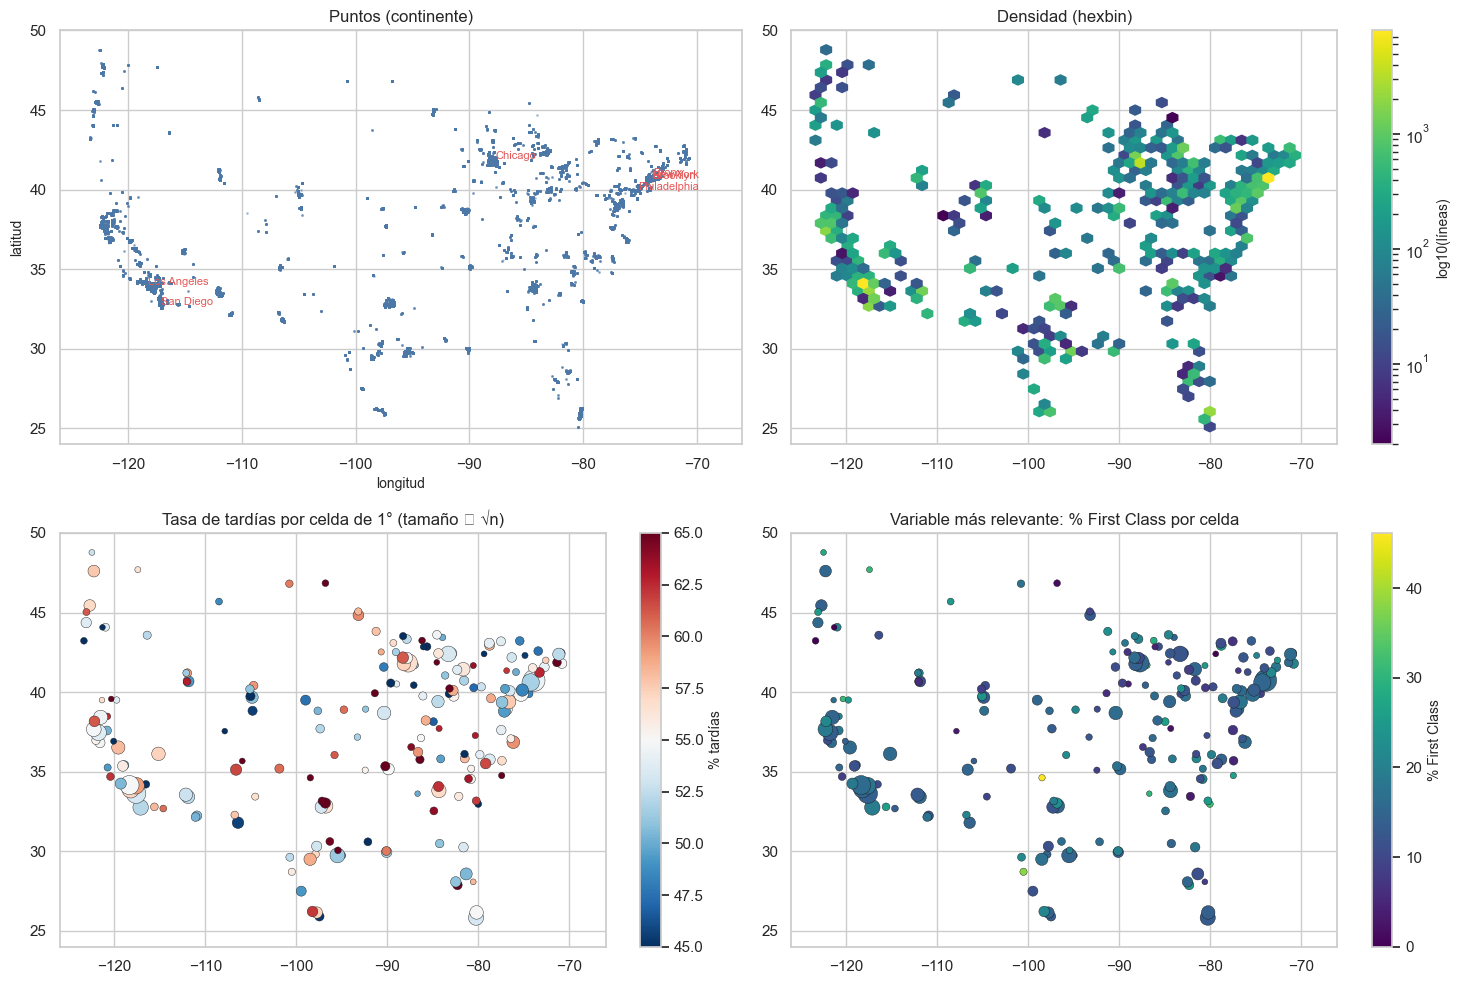

Puerto Rico (no mostrado en los mapas continentales): 54.265 líneas, 55,0 % tardías; continente: 87.638 líneas, 54,9 % tardías.

In [3]:
ok = train[[zona(a, b) in ("continental", "Puerto Rico") for a, b in zip(lat, lon)]].copy()
ok["celda"] = spatial_cells(ok[LAT], ok[LON]).to_numpy()
cel = ok.groupby("celda").agg(n=(TARGET, "size"), tasa=(TARGET, "mean"), lat=(LAT, "mean"), lon=(LON, "mean"),
                              first_class=("shipping_mode", lambda s: (s == "First Class").mean()))
cel_ok = cel[cel["n"] >= 30].copy()
top_c = ok.groupby("customer_city").agg(n=(TARGET, "size"), lat=(LAT, "median"), lon=(LON, "median")).nlargest(8, "n")

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
cont = ok[ok[LAT] > 20]
ax = axes[0, 0]
ax.scatter(cont[LON], cont[LAT], s=1, alpha=0.2, color="#4c78a8")
for c, r in top_c.iterrows():
    if r["lat"] > 20: ax.annotate(c, (r["lon"], r["lat"]), fontsize=8, color="#e45756")
ax.set_title("Puntos (continente)"); ax.set_xlabel("longitud"); ax.set_ylabel("latitud")
ax = axes[0, 1]
hb = ax.hexbin(cont[LON], cont[LAT], gridsize=45, bins="log", cmap="viridis", mincnt=1); fig.colorbar(hb, ax=ax, label="log10(líneas)")
ax.set_title("Densidad (hexbin)")
ax = axes[1, 0]
cc = cel_ok[cel_ok["lat"] > 20]
sc = ax.scatter(cc["lon"], cc["lat"], c=100 * cc["tasa"], s=np.sqrt(cc["n"]) * 3, cmap="RdBu_r", vmin=45, vmax=65, edgecolor="k", lw=0.3)
fig.colorbar(sc, ax=ax, label="% tardías"); ax.set_title("Tasa de tardías por celda de 1° (tamaño ∝ √n)")
ax = axes[1, 1]
sc = ax.scatter(cc["lon"], cc["lat"], c=100 * cc["first_class"], s=np.sqrt(cc["n"]) * 3, cmap="viridis", edgecolor="k", lw=0.3)
fig.colorbar(sc, ax=ax, label="% First Class"); ax.set_title("Variable más relevante: % First Class por celda")
for a in axes.ravel(): a.set_xlim(-126, -66); a.set_ylim(24, 50)
plt.tight_layout(); save_figure(fig, "08_mapas.png"); plt.show()
pr = ok[ok[LAT] < 20]
md_out(f"Puerto Rico (no mostrado en los mapas continentales): {es(len(pr), 0)} líneas, {es(pr[TARGET].mean(), 1, pct=True)} tardías; "
       f"continente: {es(len(cont), 0)} líneas, {es(cont[TARGET].mean(), 1, pct=True)} tardías.")

**Interpretación.** Los clientes se concentran en grandes áreas metropolitanas (Nueva
York, Los Ángeles, Chicago...) y en Puerto Rico. La tasa de tardías por celda oscila
alrededor del 55 % sin un patrón geográfico visible; las celdas extremas son las de pocas
líneas (más ruido). La proporción de envíos First Class tampoco tiene patrón espacial: el
modo de envío no depende del lugar.

## Patrón de puntos y cobertura

Índice del vecino más cercano (Clark-Evans), función K de Ripley (como L(r) − r frente a
una envolvente de aleatoriedad espacial completa, CSR) y clústeres DBSCAN con distancia
haversine. Se usan las ubicaciones únicas del continente (muestra de 2.500).

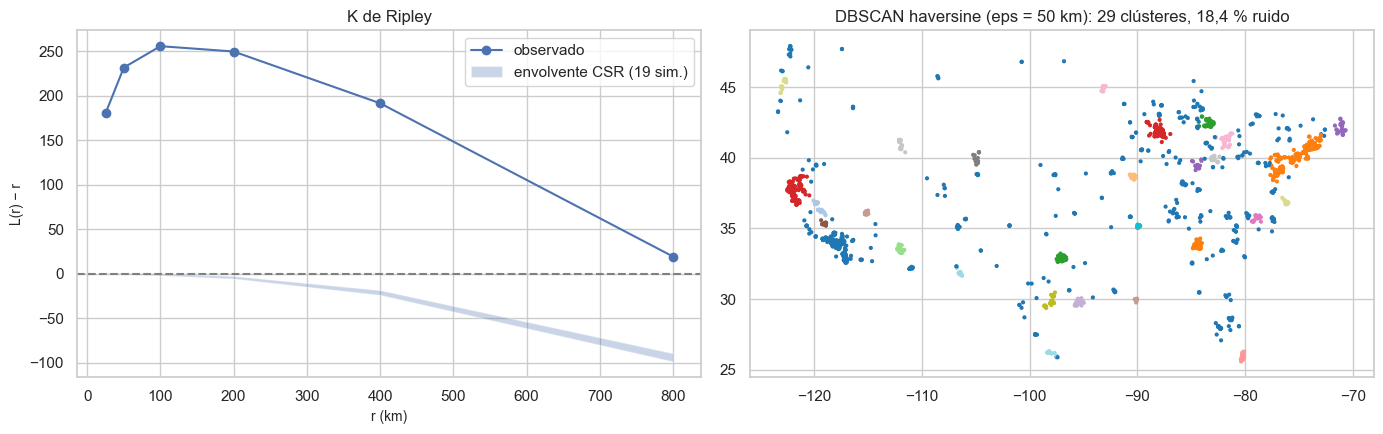

Clark-Evans R = **0,192** (z = -77,3): R < 1 indica **agrupamiento**. Área de la envolvente convexa ≈ 8,58 millones de km²; las ubicaciones ocupan solo 268 celdas de 1°.

,r_km,K,L_menos_r,CSR_min,CSR_max
0,25,132265.9,180.2,-0.6,0.8
1,50,249324.7,231.7,-0.8,1.0
2,100,397583.0,255.7,-1.8,0.2
3,200,635426.1,249.7,-5.5,-2.6
4,400,1099359.0,191.6,-23.9,-18.5
5,800,2108397.4,19.2,-98.7,-89.5


In [4]:
u = ok[ok[LAT] > 20][[LAT, LON]].drop_duplicates()
u = u.sample(min(2500, len(u)), random_state=RANDOM_STATE)
lat0 = np.radians(u[LAT].mean())
xy = np.c_[u[LON].to_numpy() * 111.32 * np.cos(lat0), u[LAT].to_numpy() * 110.57]
hull = ConvexHull(xy)
area = hull.volume                      # en 2D, .volume es el área (km²)
ce = clark_evans(u[LAT], u[LON], area)
radii = [25, 50, 100, 200, 400, 800]
rk = ripley_k(u[LAT], u[LON], radii, area)
from matplotlib.path import Path as MplPath
poly = MplPath(xy[hull.vertices])
sims = []
for b in range(19):
    pts_s = []
    while len(pts_s) < len(u):
        cand = np.c_[rng.uniform(xy[:, 0].min(), xy[:, 0].max(), 4000), rng.uniform(xy[:, 1].min(), xy[:, 1].max(), 4000)]
        pts_s.extend(cand[poly.contains_points(cand)].tolist())
    s_xy = np.array(pts_s[:len(u)])
    s_lat, s_lon = s_xy[:, 1] / 110.57, s_xy[:, 0] / (111.32 * np.cos(lat0))
    sims.append(ripley_k(s_lat, s_lon, radii, area)["L_menos_r"].to_numpy())
sims = np.array(sims)
rk["CSR_min"], rk["CSR_max"] = sims.min(axis=0), sims.max(axis=0)
rk.to_csv(TABLES / "ripley_k.csv", index=False)

db = DBSCAN(eps=50 / EARTH_RADIUS_KM, min_samples=15, metric="haversine").fit(np.radians(u[[LAT, LON]].to_numpy()))
n_cl = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(rk["r_km"], rk["L_menos_r"], "o-", label="observado"); axes[0].fill_between(rk["r_km"], rk["CSR_min"], rk["CSR_max"], alpha=0.3, label="envolvente CSR (19 sim.)")
axes[0].axhline(0, color="gray", ls="--"); axes[0].set_xlabel("r (km)"); axes[0].set_ylabel("L(r) − r"); axes[0].legend(); axes[0].set_title("K de Ripley")
axes[1].scatter(u[LON], u[LAT], c=np.where(db.labels_ < 0, -1, db.labels_), cmap="tab20", s=4)
axes[1].set_title(f"DBSCAN haversine (eps = 50 km): {n_cl} clústeres, {es((db.labels_ < 0).mean(), 1, pct=True)} ruido")
plt.tight_layout(); save_figure(fig, "08_patron_puntos.png"); plt.show()
celdas_cubiertas = cel.index.size
md_out(f"Clark-Evans R = **{es(ce['R'], 3)}** (z = {es(ce['z'], 1)}): R < 1 indica **agrupamiento**. "
       f"Área de la envolvente convexa ≈ {es(area / 1e6, 2)} millones de km²; las ubicaciones ocupan solo {celdas_cubiertas} celdas de 1°.")
display(rk.round(1))

**Interpretación.** Los puntos están fuertemente **agrupados** (R ≪ 1 y L(r) − r muy por
encima de la envolvente CSR en todas las escalas): los clientes viven en ciudades, y
amplias zonas del interior no tienen clientes. Es un **sesgo de cobertura espacial**: el
modelo no tiene información sobre zonas rurales, y cualquier conclusión espacial vale
para las áreas metropolitanas cubiertas.

## Autocorrelación espacial

**Matriz de pesos:** k = 8 vecinos más cercanos (haversine) entre centroides de celda,
estandarizada por filas. Se elige k-vecinos (y no contigüidad o banda de distancia)
porque las celdas con datos son irregulares y dispersas: una banda fija dejaría celdas
sin vecinos (Puerto Rico, costa oeste) y la contigüidad no existe entre celdas aisladas.
Se calculan la **I de Moran** global (permutaciones), los indicadores locales **LISA** y los
*hotspots* **Getis-Ord Gi\***, además del semivariograma empírico.

,variable,I,E[I],p_permutacion,z
0,tasa de tardías,0.0153,-0.005,0.570,0.5267
1,% First Class,0.0027,-0.005,0.840,0.2256
2,log(líneas) (densidad),0.1097,-0.005,0.002,3.6354


Celdas analizadas: 203. LISA significativas al 5 % sin corregir: 11; tras FDR: **0**. Celdas con |Gi*| > 1,96: 10 (se esperan ≈ 10 por azar).

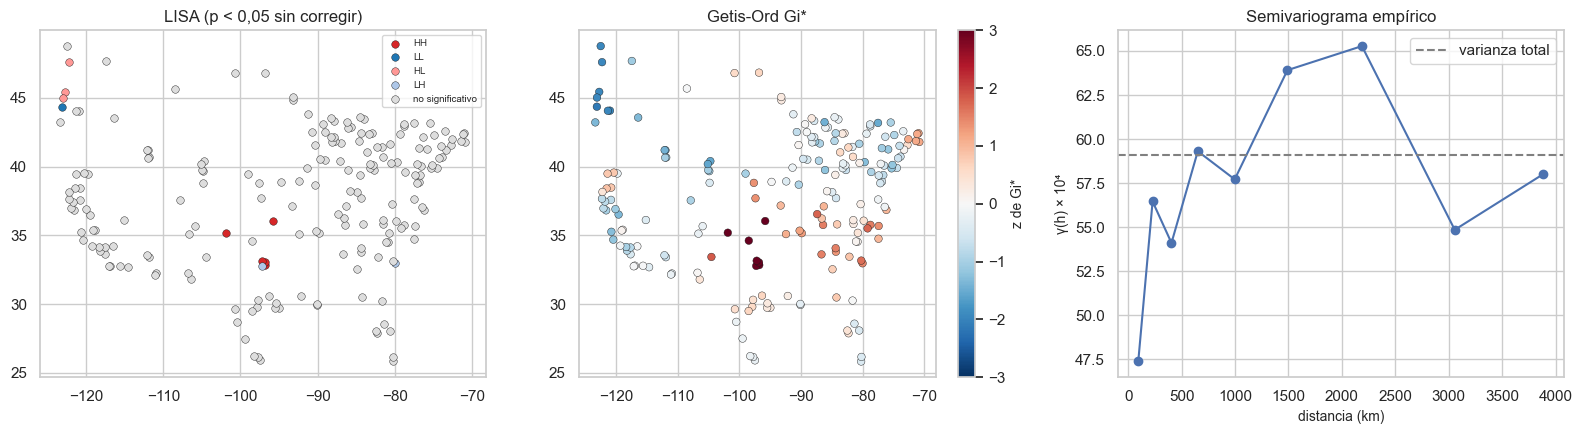

In [5]:
W = knn_weights(cel_ok["lat"], cel_ok["lon"], k=8)
mi_y = morans_i(cel_ok["tasa"], W)
mi_fc = morans_i(cel_ok["first_class"], W)
mi_n = morans_i(np.log(cel_ok["n"]), W)
moran = pd.DataFrame([{"variable": "tasa de tardías", **mi_y}, {"variable": "% First Class", **mi_fc}, {"variable": "log(líneas) (densidad)", **mi_n}])
moran.to_csv(TABLES / "moran_global.csv", index=False)
display(moran.round(4))

lisa = local_morans(cel_ok["tasa"], W, permutations=499)
lisa.index = cel_ok.index
gi = getis_ord_gi_star(cel_ok["tasa"], W)
cel_ok["lisa"] = np.where(lisa["p"] < 0.05, lisa["cuadrante"], "no significativo")
cel_ok["gi_z"] = gi
lisa_fdr = fdr_bh(lisa["p"])
cel_ok[["n", "tasa", "lisa", "gi_z"]].assign(p_lisa=lisa["p"], p_lisa_fdr=lisa_fdr).to_csv(TABLES / "lisa_gi_celdas.csv")
md_out(f"Celdas analizadas: {len(cel_ok)}. LISA significativas al 5 % sin corregir: {int((lisa['p'] < 0.05).sum())}; "
       f"tras FDR: **{int((lisa_fdr < 0.05).sum())}**. Celdas con |Gi*| > 1,96: {int((np.abs(gi) > 1.96).sum())} "
       f"(se esperan ≈ {es(0.05 * len(cel_ok), 0)} por azar).")

# Semivariograma empírico de la tasa por celda
D = haversine_km(cel_ok["lat"].to_numpy()[:, None], cel_ok["lon"].to_numpy()[:, None], cel_ok["lat"].to_numpy()[None, :], cel_ok["lon"].to_numpy()[None, :])
v = cel_ok["tasa"].to_numpy()
iu = np.triu_indices(len(v), 1)
dd, gg = D[iu], 0.5 * (v[iu[0]] - v[iu[1]]) ** 2
bins = np.array([0, 150, 300, 500, 800, 1200, 1800, 2600, 3600, 5000])
semiv = pd.DataFrame({"d": dd, "g": gg}).assign(bin=pd.cut(dd, bins)).groupby("bin", observed=True).agg(dist=("d", "mean"), gamma=("g", "mean"), pares=("g", "size"))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
cc = cel_ok[cel_ok["lat"] > 20]
colores = {"HH": "#d62728", "LL": "#1f77b4", "HL": "#ff9896", "LH": "#aec7e8", "no significativo": "#dddddd"}
for k, c in colores.items():
    m = cc["lisa"] == k
    axes[0].scatter(cc.loc[m, "lon"], cc.loc[m, "lat"], color=c, s=30, label=k, edgecolor="k", lw=0.3)
axes[0].legend(fontsize=7); axes[0].set_title("LISA (p < 0,05 sin corregir)")
sc = axes[1].scatter(cc["lon"], cc["lat"], c=cc["gi_z"], cmap="RdBu_r", vmin=-3, vmax=3, s=30, edgecolor="k", lw=0.3)
fig.colorbar(sc, ax=axes[1], label="z de Gi*"); axes[1].set_title("Getis-Ord Gi*")
axes[2].plot(semiv["dist"], semiv["gamma"] * 1e4, "o-"); axes[2].axhline(np.var(v) * 1e4, ls="--", color="gray", label="varianza total")
axes[2].set_xlabel("distancia (km)"); axes[2].set_ylabel("γ(h) × 10⁴"); axes[2].legend(); axes[2].set_title("Semivariograma empírico")
plt.tight_layout(); save_figure(fig, "08_autocorrelacion.png"); plt.show()

**Interpretación.** La I de Moran de la tasa de tardías es cercana a su valor esperado
bajo aleatoriedad y **no significativa**; el semivariograma es plano (sin rango ni
meseta: la semivarianza ya está en el nivel de la varianza total a cualquier distancia),
y tras corregir por comparaciones múltiples no quedan *clusters* locales. Las celdas
«significativas» sin corrección son las esperables por azar. En cambio, la **densidad**
de clientes sí está autocorrelacionada (las ciudades grandes tienen vecinos densos):
existe estructura espacial en la población, **no en el objetivo**.

## Heterogeneidad espacial y efecto de la escala (MAUP)

In [6]:
het = (ok.assign(zona=np.where(ok[LAT] < 20, "Puerto Rico", "continente"))
       .groupby(["zona", "shipping_mode"])[TARGET].agg(["mean", "size"]).unstack(0))
display((het["mean"] * 100).round(2))
est = rate_table(ok["customer_state"], ok[TARGET], min_n=500)
v_st, chi_st, p_st = cramers_v(ok["customer_state"], ok[TARGET])
md_out(f"Estado del cliente vs objetivo: χ² = {es(chi_st, 1)}, p = {p_st:.3f}, V de Cramér = {es(v_st, 3)}; "
       f"tasa por estado (≥ 500 líneas) entre {es(est['tasa'].min(), 1, pct=True)} y {es(est['tasa'].max(), 1, pct=True)}.")

maup = []
for size in [0.5, 1.0, 2.0, 4.0]:
    c2 = ok.assign(c=spatial_cells(ok[LAT], ok[LON], size).to_numpy()).groupby("c").agg(n=(TARGET, "size"), tasa=(TARGET, "mean"), lat=(LAT, "mean"), lon=(LON, "mean"))
    c2 = c2[c2["n"] >= 30]
    r = morans_i(c2["tasa"], knn_weights(c2["lat"], c2["lon"], k=min(8, len(c2) - 1)), permutations=499)
    maup.append({"celda_grados": size, "celdas": len(c2), "I_Moran": r["I"], "p": r["p_permutacion"]})
maup = pd.DataFrame(maup)
maup.to_csv(TABLES / "maup_moran.csv", index=False)
display(maup.round(4))

ok["dist_caguas_km"] = haversine_km(ok[LAT], ok[LON], 18.2342, -66.0485)
centro_ny = (40.71, -74.0)
ok["dist_ny_km"] = haversine_km(ok[LAT], ok[LON], *centro_ny)
dist_auc = pd.DataFrame([{"variable": c, "AUC univariado": univariate_auc(ok[c], ok[TARGET])} for c in [LAT, LON, "dist_caguas_km", "dist_ny_km"]])
dist_auc.to_csv(TABLES / "auc_espaciales.csv", index=False)
display(dist_auc.round(4))

zona,Puerto Rico,continente
shipping_mode,,
First Class,96.04,95.35
Same Day,42.02,46.19
Second Class,76.71,76.82
Standard Class,38.43,38.03


Estado del cliente vs objetivo: χ² = 124,0, p = 0.000, V de Cramér = 0,024; tasa por estado (≥ 500 líneas) entre 50,6 % y 61,4 %.

,celda_grados,celdas,I_Moran,p
0,0.5,185,0.0003,0.888
1,1.0,203,0.0153,0.558
2,2.0,116,-0.0148,0.872
3,4.0,52,-0.0664,0.388


,variable,AUC univariado
0,latitude,0.5008
1,longitude,0.5002
2,dist_caguas_km,0.5004
3,dist_ny_km,0.5004


**Interpretación.** La relación entre el modo de envío y el retraso es **la misma** en
Puerto Rico y en el continente (no hay heterogeneidad espacial de la relación), y el
estado del cliente apenas se asocia con el objetivo. El resultado de Moran **no depende
de la escala** de agregación (0,5° a 4°): no es un artefacto del MAUP. Las variables
espaciales construidas (distancia haversine al principal núcleo, Caguas, o a Nueva York) y
las coordenadas crudas tienen AUC ≈ 0,50.

**Decisión sobre ingeniería espacial:** no se incluyen latitud/longitud crudas ni
distancias en el modelo base: no tienen señal y las coordenadas crudas en un modelo lineal
solo capturarían gradientes norte-sur/este-oeste inexistentes. Se documenta como hallazgo
negativo del EDA.

## Destino del pedido (sin coordenadas)

El destino solo tiene país, región y mercado. Como se vio en el capítulo 7, **el mercado
de destino rota en el tiempo**; aquí se mide cuánto del destino se explica por el periodo.

In [7]:
trim = train[DATE_COL].dt.to_period("Q").astype(str)
v_mq, _, _ = cramers_v(train["market"], trim)
v_rq, _, _ = cramers_v(train["order_region"], trim)
v_ry, _, p_ry = cramers_v(train["order_region"], y)
md_out(f"- V de Cramér mercado × trimestre = **{es(v_mq, 3)}**; región × trimestre = **{es(v_rq, 3)}**.\n"
       f"- V de Cramér región de destino × objetivo = {es(v_ry, 3)} (p = {p_ry:.3f}).")

- V de Cramér mercado × trimestre = **0,777**; región × trimestre = **0,576**.
- V de Cramér región de destino × objetivo = 0,018 (p = 0.000).

**Interpretación.** El destino está casi determinado por el trimestre (V alta) y no se
asocia con el objetivo. En un modelo, las variables de destino actuarían como un
**indicador del periodo**, y su efecto aprendido en un periodo no se trasladaría a otro.

## Consecuencias para el modelado (2.7)

Como el objetivo **no** tiene autocorrelación espacial, la validación aleatoria por
ubicación no estaría inflada por vecindad. Aun así, el enunciado pide verificarlo: el
capítulo 11 reporta, **por separado**, una validación por **bloques espaciales**
(`GroupKFold` por celdas de 1°) además de la validación temporal principal.

# Componente espacio-temporal (2.8)

## Mapas por periodo y series por zona

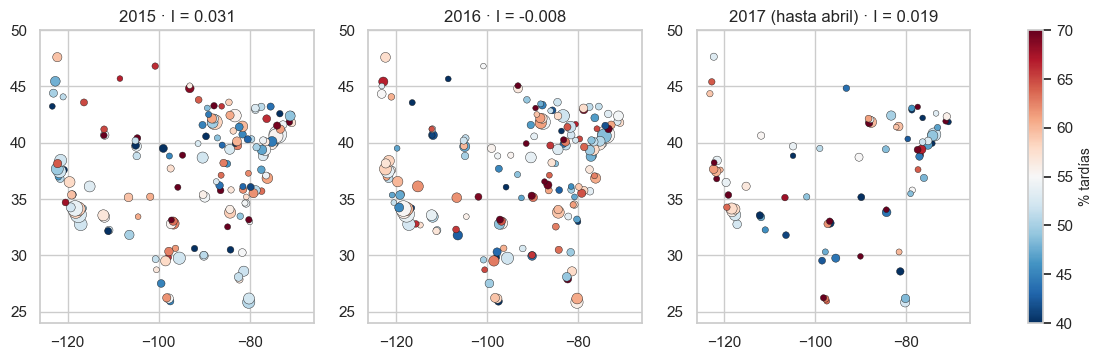

,año,celdas,líneas,I_Moran,p
0,2015,161,62163,0.0313,0.328
1,2016,174,62015,-0.0084,0.952
2,2017,81,17725,0.0185,0.520


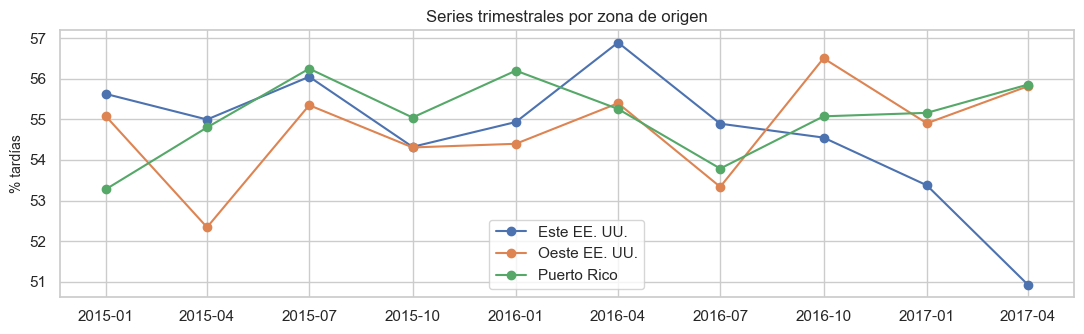

In [8]:
ok["anio"] = ok[DATE_COL].dt.year
anios = sorted(ok["anio"].unique())
fig, axes = plt.subplots(1, len(anios), figsize=(5 * len(anios), 3.8))
moran_anio = []
for ax, a in zip(axes, anios):
    sub = ok[ok["anio"] == a]
    c2 = sub.groupby("celda").agg(n=(TARGET, "size"), tasa=(TARGET, "mean"), lat=(LAT, "mean"), lon=(LON, "mean"))
    c2 = c2[c2["n"] >= 30]
    r = morans_i(c2["tasa"], knn_weights(c2["lat"], c2["lon"], k=8), permutations=499)
    moran_anio.append({"año": a, "celdas": len(c2), "líneas": len(sub), "I_Moran": r["I"], "p": r["p_permutacion"]})
    cc = c2[c2["lat"] > 20]
    sc = ax.scatter(cc["lon"], cc["lat"], c=100 * cc["tasa"], cmap="RdBu_r", vmin=40, vmax=70, s=np.sqrt(cc["n"]) * 3, edgecolor="k", lw=0.3)
    ax.set_title(f"{a}{' (hasta abril)' if a == 2017 else ''} · I = {r['I']:.3f}"); ax.set_xlim(-126, -66); ax.set_ylim(24, 50)
fig.colorbar(sc, ax=axes, label="% tardías")
save_figure(fig, "08_mapas_por_anio.png"); plt.show()
moran_anio = pd.DataFrame(moran_anio)
moran_anio.to_csv(TABLES / "moran_por_anio.csv", index=False)
display(moran_anio.round(4))

serie_zona = (ok.assign(zona=np.where(ok[LAT] < 20, "Puerto Rico", np.where(ok[LON] < -100, "Oeste EE. UU.", "Este EE. UU.")),
                        q=ok[DATE_COL].dt.to_period("Q"))
              .groupby(["q", "zona"])[TARGET].mean().unstack())
fig, ax = plt.subplots(figsize=(11, 3.5))
for c in serie_zona.columns:
    ax.plot(serie_zona.index.to_timestamp(), 100 * serie_zona[c], "o-", label=c)
ax.set_ylabel("% tardías"); ax.legend(); ax.set_title("Series trimestrales por zona de origen")
plt.tight_layout(); save_figure(fig, "08_series_por_zona.png"); plt.show()

## Interacción espacio-tiempo: persistencia de *hotspots* y prueba de Knox

¿Los patrones espaciales cambian con el tiempo? Se compara la tasa por celda entre
2015 y 2016 (si hubiera *hotspots* persistentes, la correlación sería positiva) y se aplica
la **prueba de Knox**: entre pares de entregas tardías, ¿hay más pares cercanos a la vez en
espacio (< 50 km) y tiempo (< 7 días) de lo esperado si tiempo y espacio fueran
independientes? (999 permutaciones de las fechas.)

In [9]:
pv = ok[ok["anio"].isin([2015, 2016])].groupby(["celda", "anio"])[TARGET].agg(["mean", "size"]).unstack()
pv = pv[(pv["size"] >= 30).all(axis=1)]
rho, p_rho = stats.spearmanr(pv["mean"][2015], pv["mean"][2016])
gi15 = getis_ord_gi_star(pv["mean"][2015], knn_weights(cel.loc[pv.index, "lat"], cel.loc[pv.index, "lon"], 8))
gi16 = getis_ord_gi_star(pv["mean"][2016], knn_weights(cel.loc[pv.index, "lat"], cel.loc[pv.index, "lon"], 8))
md_out(f"Celdas con ≥ 30 líneas en 2015 y 2016: {len(pv)}. Correlación de Spearman de la tasa por celda entre años: "
       f"**ρ = {es(rho, 3)}** (p = {p_rho:.3f}); correlación de los Gi*: {es(np.corrcoef(gi15, gi16)[0, 1], 3)}.")

late = ok[ok[TARGET] == 1].drop_duplicates(ORDER_COL)
late = late[late[LAT] > 20].sample(3000, random_state=RANDOM_STATE)
la_, lo_ = late[LAT].to_numpy(), late[LON].to_numpy()
t_ = (late[DATE_COL] - late[DATE_COL].min()).dt.total_seconds().to_numpy() / 86400
Ds = haversine_km(la_[:, None], lo_[:, None], la_[None, :], lo_[None, :])
iu = np.triu_indices(len(la_), 1)
close_s = Ds[iu] < 50
def knox(tt):
    return int(np.sum(close_s & (np.abs(tt[iu[0]] - tt[iu[1]]) < 7)))
obs = knox(t_)
sims = np.array([knox(rng.permutation(t_)) for _ in range(199)])
p_knox = (1 + np.sum(sims >= obs)) / 200
knox_df = pd.DataFrame([{"pares_cercanos_espacio": int(close_s.sum()), "pares_cercanos_espacio_y_tiempo": obs,
                         "esperado_bajo_independencia": float(sims.mean()), "p_permutacion": p_knox}])
knox_df.to_csv(TABLES / "knox.csv", index=False)
display(knox_df.round(3))

Celdas con ≥ 30 líneas en 2015 y 2016: 157. Correlación de Spearman de la tasa por celda entre años: **ρ = -0,055** (p = 0.491); correlación de los Gi*: -0,107.

,pares_cercanos_espacio,pares_cercanos_espacio_y_tiempo,esperado_bajo_independencia,p_permutacion
0,152056,2417,2528.925,0.995


## Consecuencias para el modelado (2.8) e interpretación

- **Dinámica espacio-temporal:** la tasa por celda **no persiste** de un año a otro (ρ ≈ 0) y
  la prueba de Knox no detecta agrupamiento conjunto en espacio y tiempo de las entregas
  tardías: no hay *hotspots* que aparezcan, se desplacen o persistan. La I de Moran es
  no significativa en cada año.
- **Objetivo de predicción:** el uso previsto es **predecir pedidos futuros** de los mismos
  clientes y zonas, así que la partición principal es **cronológica**. Generalizar a zonas
  nuevas es secundario: se reporta como esquema adicional (bloques espaciales) en el
  capítulo 11, por separado.
- **Riesgo de fuga por vecindad:** bajo en el espacio (sin autocorrelación del objetivo). El
  riesgo relevante es **temporal** (etiquetas que se conocen con retraso), cubierto por el *gap*.
- **El destino** (mercado/región/país) está confundido con el periodo por la rotación de
  mercados; su inclusión en el modelo se decide con validación temporal en el capítulo 10.